# Steepest Descent and Modified Newton on the Rosenbrock Function

Compare first-order and curvature-aware minimization of the nonconvex Rosenbrock function from the same starting point. Both methods use Armijo backtracking, and their trajectories, objective values, distances to the minimizer and accepted step lengths are recorded.

The unique global minimizer is $(1,1)$ because the objective is a sum of nonnegative squares and vanishes only there.

[Technical notes](../docs/steepest_descent_and_modified_newton.md) · [Saved figures](../results/steepest_descent_and_modified_newton/)

In [2]:
import numpy as np
import matplotlib.pyplot as plt

## Rosenbrock objective

$$f(x)=100(x_2-x_1^2)^2+(1-x_1)^2.$$

Its narrow curved valley makes steepest descent challenging.

In [3]:
def f(x):
    x1, x2 = x
    return 100*(x2 - x1**2)**2 + (1 - x1)**2

## Gradient

$$\nabla f(x)=\begin{bmatrix}-400x_1(x_2-x_1^2)-2(1-x_1)\\200(x_2-x_1^2)\end{bmatrix}.$$

In [4]:
def grad(x):
    x1, x2 = x
    return np.array([
        -400*x1*(x2 - x1**2) - 2*(1 - x1),
        200*(x2 - x1**2)
    ])

## Hessian and curvature

$$\nabla^2 f(x)=\begin{bmatrix}1200x_1^2-400x_2+2&-400x_1\\-400x_1&200\end{bmatrix}.$$

At $(1,1)$ the eigenvalues are approximately 1001.6 and 0.399; the pronounced scale difference explains ill-conditioning. At $(0,1)$ the first diagonal entry is negative, so the function is not globally convex.

In [5]:
def hessian(x):
    x1, x2 = x
    return np.array([
        [1200*x1**2 - 400*x2 + 2, -400*x1],
        [-400*x1, 200]
    ])

## Armijo backtracking

Starting from $\alpha_0=1$, reduce the trial step by $\beta=0.5$ until $f(x+\alpha p)\le f(x)+\sigma\alpha g^Tp$, with $\sigma=0.1$.

In [6]:
def backtracking(x, p, g, alpha0=1.0, beta=0.5, sigma=0.1):
    """
    Armijo backtracking line search.

    x     : current point
    p     : search direction
    g     : gradient at x
    alpha0: initial step size
    beta  : contraction factor in (0,1)
    sigma : Armijo constant in (0,1)
    """
    alpha = alpha0
    fx = f(x)
    while f(x + alpha * p) > fx + sigma * alpha * np.dot(g, p):
        alpha *= beta
    return alpha

## Steepest descent

Use $p_k=-\nabla f(x_k)$ and stop when the gradient norm falls below $10^{-6}$. The recorded histories support convergence diagnostics.

In [7]:
def steepest_descent(x0, tol=1e-6, max_iter=20000):
    """
    Steepest Descent with backtracking.

    Returns:
        xs      : list of iterates
        fvals   : list of f(x_k)
        norms   : list of ||x_k - x*||
        alphas  : list of step sizes
        conv_it : iteration of convergence (or None)
    """
    x = x0.copy()
    xs, fvals, norms, alphas = [], [], [], []
    conv_it = None
    x_star = np.array([1.0, 1.0])  # true minimizer

    for k in range(max_iter):
        g = grad(x)
        p = -g
        alpha = backtracking(x, p, g)

        xs.append(x.copy())
        fvals.append(f(x))
        norms.append(np.linalg.norm(x - x_star))
        alphas.append(alpha)

        if np.linalg.norm(g) < tol and conv_it is None:
            conv_it = k
            break

        x = x + alpha * p

    return xs, fvals, norms, alphas, conv_it


## Configurable initial trial step

The same sufficient-decrease test is used with an externally supplied initial step.

In [8]:
def backtracking_alpha0(x, p, g, alpha0, beta=0.5, sigma=0.1):
    """
    Backtracking line search starting from a given alpha0.
    """
    alpha = alpha0
    fx = f(x)
    # Armijo condition: f(x + αp) <= f(x) + σ α g^T p
    while f(x + alpha * p) > fx + sigma * alpha * np.dot(g, p):
        alpha *= beta
    return alpha

## Step-size sensitivity solver

This variant records the convergence index for a given initial trial step, allowing a controlled comparison.

In [9]:
def steepest_descent_alpha0(x0, alpha0, tol=1e-6, max_iter=20000):
    """
    Steepest Descent using backtracking that starts from alpha0.
    Returns the iteration at which convergence happens (or None).
    """
    x = x0.copy()
    conv_iter = None

    for k in range(max_iter):
        g = grad(x)
        if np.linalg.norm(g) < tol:
            conv_iter = k
            break

        p = -g
        alpha = backtracking_alpha0(x, p, g, alpha0)
        x = x + alpha * p

    return conv_iter

## Modified Newton method

Solve $H_kp_k=-g_k$ after shifting the Hessian by $(-\lambda_{\min}+10^{-3})I$ when its smallest eigenvalue is nonpositive. The shift produces positive curvature; backtracking globalizes the step.

In [10]:
def modified_newton(x0, tol=1e-6, max_iter=3000):
    """
    Modified Newton with backtracking.
    Hessian is shifted to be positive definite if needed.

    Returns:
        xs      : list of iterates
        fvals   : list of f(x_k)
        norms   : list of ||x_k - x*||
        alphas  : list of step sizes
        conv_it : iteration of convergence (or None)
    """
    x = x0.copy()
    xs, fvals, norms, alphas = [], [], [], []
    conv_it = None
    x_star = np.array([1.0, 1.0])  # true minimizer

    for k in range(max_iter):
        g = grad(x)
        H = hessian(x)

        # Ensure H is positive definite
        eigvals = np.linalg.eigvals(H)
        min_ev = np.min(eigvals)
        if min_ev <= 0:
            H = H + np.eye(2) * (-min_ev + 1e-3)

        p = -np.linalg.solve(H, g)
        alpha = backtracking(x, p, g)

        xs.append(x.copy())
        fvals.append(f(x))
        norms.append(np.linalg.norm(x - x_star))
        alphas.append(alpha)

        if np.linalg.norm(g) < tol and conv_it is None:
            conv_it = k
            break

        x = x + alpha * p

    return xs, fvals, norms, alphas, conv_it


## Shared initialization and numerical comparison

Both methods start at $(-1,2)$ with the same gradient tolerance.

In [11]:
x0 = np.array([-1.0, 2.0])
xs_sd, fvals_sd, norms_sd, alphas_sd, conv_sd = steepest_descent(x0)
xs_nt, fvals_nt, norms_nt, alphas_nt, conv_nt = modified_newton(x0)

# After gradient method finishes:
print("\n=== Steepest Descent Results ===")
print("Convergence iteration:", conv_sd)
print("Final point x_sd =", xs_sd[-1])
print("Final function value f(x_sd) =", f(xs_sd[-1]))

# After Newton method finishes:
print("\n=== Modified Newton Results ===")
print("Convergence iteration:", conv_nt)
print("Final point x_nt =", xs_nt[-1])
print("Final function value f(x_nt) =", f(xs_nt[-1]))


=== Steepest Descent Results ===
Convergence iteration: 13727
Final point x_sd = [0.99999917 0.99999833]
Final function value f(x_sd) = 6.927278456857628e-13

=== Modified Newton Results ===
Convergence iteration: 25
Final point x_nt = [1. 1.]
Final function value f(x_nt) = 7.468830665648636e-21


## Initial trial-step experiment

Compare five initial trial steps while retaining the Armijo reduction and stopping criterion.

In [12]:
alpha0_list = [0.1, 0.5, 1.0, 2.0, 5.0]
results = {}

for a0 in alpha0_list:
    conv = steepest_descent_alpha0(x0, a0)
    results[a0] = conv

print("Convergence iterations for different alpha0 values:")
for a0 in alpha0_list:
    print(f"alpha0 = {a0:4.1f}  -->  convergence iteration: {results[a0]}")

Convergence iterations for different alpha0 values:
alpha0 =  0.1  -->  convergence iteration: 13414
alpha0 =  0.5  -->  convergence iteration: 12577
alpha0 =  1.0  -->  convergence iteration: 13727
alpha0 =  2.0  -->  convergence iteration: 13727
alpha0 =  5.0  -->  convergence iteration: 7361


## Steepest descent convergence plots

Inspect the decrease in objective value, distance to the solution and accepted step sizes.

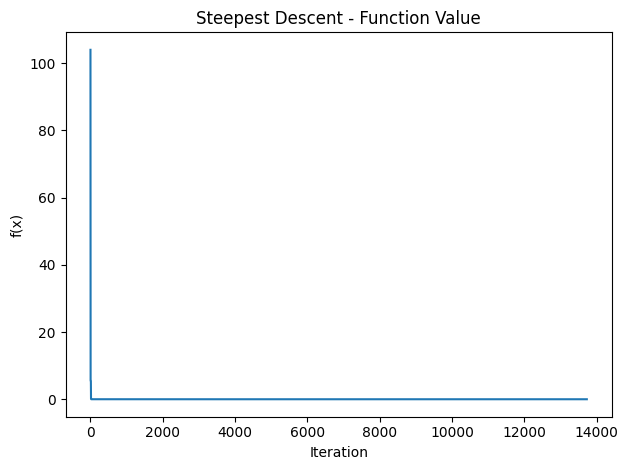

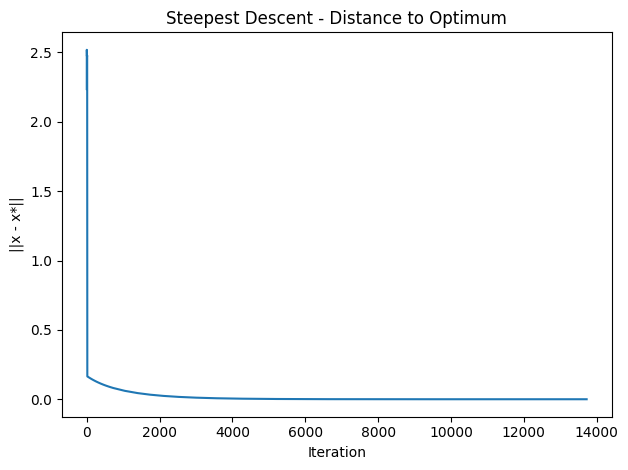

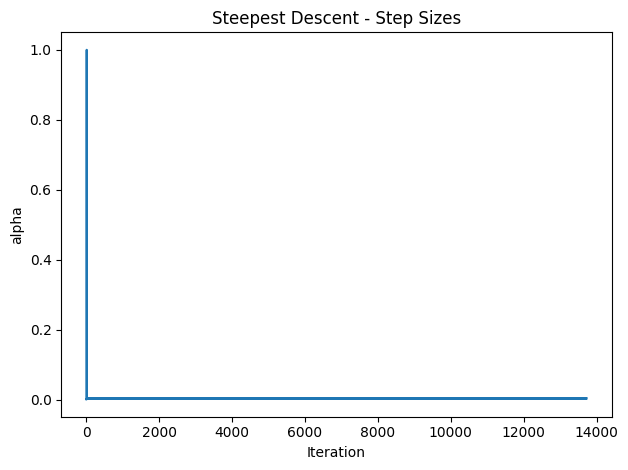

In [29]:
plt.figure()
plt.plot(fvals_sd)
plt.title("Steepest Descent - Function Value")
plt.xlabel("Iteration")
plt.ylabel("f(x)")
plt.tight_layout()
plt.savefig("sd_fvals.png", dpi=300)

plt.figure()
plt.plot(norms_sd)
plt.title("Steepest Descent - Distance to Optimum")
plt.xlabel("Iteration")
plt.ylabel("||x - x*||")
plt.tight_layout()
plt.savefig("sd_dist.png", dpi=300)

plt.figure()
plt.plot(alphas_sd)
plt.title("Steepest Descent - Step Sizes")
plt.xlabel("Iteration")
plt.ylabel("alpha")
plt.tight_layout()
plt.savefig("sd_alpha.png", dpi=300)
plt.show()

## Modified Newton convergence plots

The same diagnostics reveal the much shorter curvature-aware trajectory.

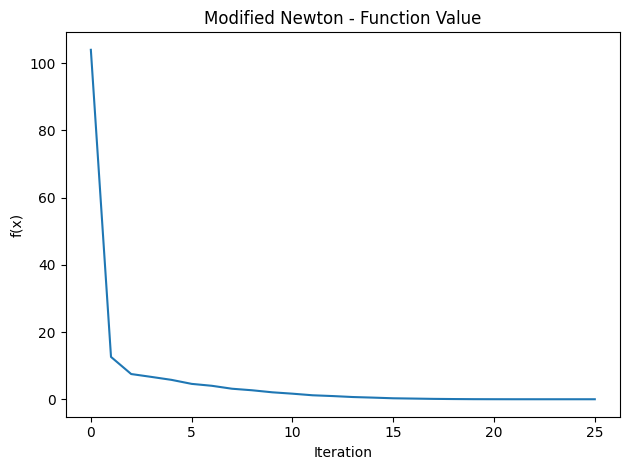

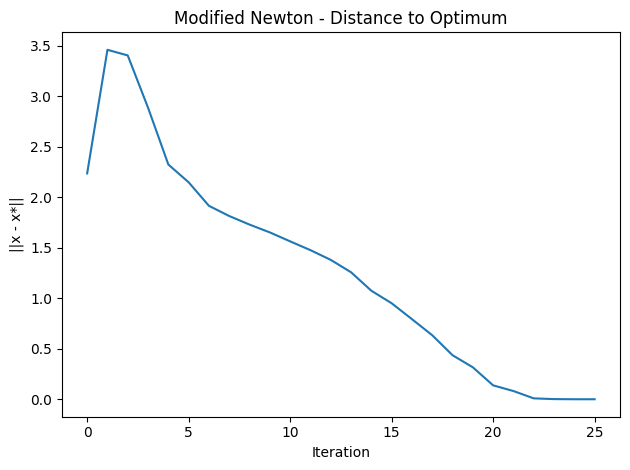

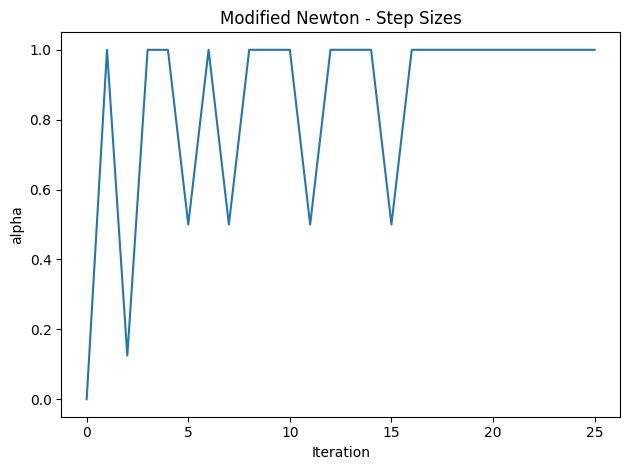

In [30]:
plt.figure()
plt.plot(fvals_nt)
plt.title("Modified Newton - Function Value")
plt.xlabel("Iteration")
plt.ylabel("f(x)")
plt.tight_layout()
plt.savefig("newton_fvals.png", dpi=300)

plt.figure()
plt.plot(norms_nt)
plt.title("Modified Newton - Distance to Optimum")
plt.xlabel("Iteration")
plt.ylabel("||x - x*||")
plt.tight_layout()
plt.savefig("newton_dist.png", dpi=300)

plt.figure()
plt.plot(alphas_nt)
plt.title("Modified Newton - Step Sizes")
plt.xlabel("Iteration")
plt.ylabel("alpha")
plt.tight_layout()
plt.savefig("newton_alpha.png", dpi=300)
plt.show()

## Results and interpretation

| Method | Reported convergence index | Final objective |
|---|---:|---:|
| Steepest descent | 13,727 | $6.9273\times10^{-13}$ |
| Modified Newton | 25 | $7.4688\times10^{-21}$ |

Steepest descent ends at approximately $(0.99999917,0.99999833)$; modified Newton reaches $(1,1)$ to the displayed precision. The difference in iteration counts illustrates the benefit of exploiting local curvature in the Rosenbrock valley. It is not a runtime comparison: Newton iterations have a higher per-step computational cost.

| Initial trial step | Steepest descent convergence index |
|---:|---:|
| 0.1 | 13,414 |
| 0.5 | 12,577 |
| 1 | 13,727 |
| 2 | 13,727 |
| 5 | 7,361 |

Among these settings, 5 gives the smallest iteration count. Backtracking means that the initial trial step is not the actual step, and the relationship between trial step and convergence is not monotone. The objective decreases under accepted Armijo steps, whereas Euclidean distance need not decrease monotonically. The results are specific to this initialization, tolerance and implementation.